# Lab 2 · Task 2 — Fine-tuning pretrained models
**Machine Learning for Sound and Music**

This notebook adapts pretrained networks to the genre task and evaluates them.

| Step | Content |
|---|---|
| 1 | **Setup** — Drive, local copy of the spectrograms, configuration |
| 2 | **Data** — load the shared split (`split_seed42.json`) |
| 3 | **Functions** — data pipeline, models, two-phase fine-tuning, result logging |
| 4 | **Pretrained vision models** — VGG16, ResNet50, EfficientNetB0 (ImageNet) × 4 fine-tuning strategies = 12 configurations |
| 5 | **Model selection** — by validation accuracy; test evaluation of the selected model |
| 6 | **SpecAugment check** — the selected configuration trained with the masking used in Task 1 |
| 7 | **Frozen VGG16 embeddings** + classical classifiers |
| 8 | **VGGish** (audio model) — frozen embeddings + classical classifiers *(exploratory)* |
| 9 | **Final table** |

**Protocol.** Configurations are compared with the validation accuracy (80 songs). The test accuracy of all 12 configurations is reported for completeness but is **not** used to choose.

**Resuming.** Every finished run is stored in `runs.csv` and finished runs are **not retrained**, so after a Colab disconnection (or to re-run the notebook for the final report) simply run it again from the top. The per-epoch training log of every run is stored in `training_logs.json` and **replayed** when a run is skipped, so the logs stay visible without training anything. With all runs already stored, the notebook only reloads results (no GPU needed).

**Outputs** (all in `results_task2/`; the file names are read by the later notebooks):

| File | Content |
|---|---|
| `runs.csv` | One row per model: validation / test accuracy, training time, inference time, parameters |
| `probs_<model>.npy`, `test_labels.npy` | Test-set class probabilities of every model (same song order as the split) |
| `vggish_{train,val,test}.npz` | Cached VGGish embeddings |
| `training_logs.json` | Per-epoch training log (text) of every run, replayed when the run is skipped |
| `pipeline_config.json` | Crop / size / batch size the results were produced with |
| `task2_fig_*.png` | Figures used in the report |

## Setup

Two switches control whether results already stored in Drive are reused:

- `FORCE_USE_EXISTING` — allow `runs.csv` to be reused when its pipeline configuration is unknown.
- `FORCE_RERUN_SKLEARN` — recompute the classical classifiers on the frozen embeddings even if they are already stored. Leave it `False` to reproduce the reported timings.
- `SHOW_LOGS` — replay the stored training log of the runs that are skipped (`True`), or only print one line per skipped run (`False`).

In [1]:
from google.colab import drive
drive.mount("/content/drive")

import os, shutil
from pathlib import Path

# ---- Paths ----
PROJECT      = Path("/content/drive/MyDrive/MSC/music-genre-classification-2")
SRC_IMAGES   = PROJECT / "data" / "images_original"      # spectrograms on Drive
LOCAL_IMAGES = Path("/content/data/images_original")     # local copy (faster I/O)
WAV_DIR      = PROJECT / "data" / "genres_original"      # WAV files (only read once, for VGGish)
SPLIT_FILE   = PROJECT / "split_seed42.json"             # shared split (Task 1, Task 2, Lab 1)
WORK_DIR     = PROJECT / "results_task2"                 # runs.csv, probs_*.npy, VGGish caches
WORK_DIR.mkdir(exist_ok=True)
os.chdir(WORK_DIR)                                       # relative np.save / np.savez calls write to Drive

assert SRC_IMAGES.exists(), f"Spectrogram folder not found: {SRC_IMAGES}"

n_local = len(list(LOCAL_IMAGES.glob("*/*.png"))) if LOCAL_IMAGES.exists() else 0
if n_local < 900:
    print("Copying spectrograms to local disk ...")
    shutil.copytree(SRC_IMAGES, LOCAL_IMAGES, dirs_exist_ok=True,
                    ignore=shutil.ignore_patterns(".DS_Store", "._*"))
print("Local PNG files:", len(list(LOCAL_IMAGES.glob("*/*.png"))),
      "| WAV folder on Drive:", WAV_DIR.exists())

Mounted at /content/drive
Copying spectrograms to local disk ...
Local PNG files: 999 | WAV folder on Drive: True


### 1.1 Imports and configuration
The spectrograms receive exactly the preprocessing of Task 1 (crop the figure frame, RGBA → RGB), but are resized to **160 × 240** pixels (frequency × time) for the pretrained networks. The three colour channels are kept, and every network receives the input preprocessing it was trained with (mean subtraction for VGG16 / ResNet50; EfficientNetB0 rescales internally).

In [2]:
import gc, io, re, sys, json, time, warnings, contextlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from IPython.display import display
from tensorflow import keras
from tensorflow.keras import layers
from scipy.stats import spearmanr
from sklearn.model_selection import train_test_split
from sklearn.metrics import (classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, accuracy_score)

plt.rcParams.update({"figure.dpi": 110, "axes.grid": False,
                     "axes.spines.top": False, "axes.spines.right": False})

# ---- Configuration ----
SEED     = 42
DATA_DIR = LOCAL_IMAGES
IMG_SIZE = (160, 240)            # (height = frequency, width = time); similar aspect ratio to the cropped 213x332 spectrogram
CROP     = (55, 37, 387, 250)    # (left, top, right, bottom): spectrogram only, no white frame or axes
BATCH    = 32
WEIGHTS  = "imagenet"            # None = random initialisation (only for debugging)

FORCE_USE_EXISTING  = False      # True only if runs.csv was produced with this same crop and size
FORCE_RERUN_SKLEARN = False      # True: recompute the classical classifiers of Sections 7-8
SHOW_LOGS           = True       # replay the stored training log of runs that are skipped

keras.utils.set_random_seed(SEED)
assert DATA_DIR.exists(), f"Not found: {DATA_DIR}"
print("TensorFlow", tf.__version__, "| Keras", keras.__version__)
gpus = tf.config.list_physical_devices("GPU")
print("GPUs:", gpus)
if not gpus:
    print("WARNING: no GPU. Fine if every run is already stored in runs.csv; otherwise switch to a GPU runtime.")

TensorFlow 2.21.0 | Keras 3.13.2
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]



Safety Check: Results obtained with a different crop or image size must never be mixed in the same folder. The pipeline configuration is stored next to the results and checked on every run.

In [3]:
CFG_FILE = WORK_DIR / "pipeline_config.json"
cfg_now  = dict(img_size=list(IMG_SIZE), crop=list(CROP), batch=BATCH)

if CFG_FILE.exists():
    assert json.load(open(CFG_FILE)) == cfg_now, \
        "results_task2 holds results from a different pipeline (crop / size): rename that folder."
elif (WORK_DIR / "runs.csv").exists() and not FORCE_USE_EXISTING:
    raise RuntimeError("runs.csv exists but the crop / size it was produced with is unknown. "
                       "Rename the folder to start again, or set FORCE_USE_EXISTING = True.")
else:
    json.dump(cfg_now, open(CFG_FILE, "w"))
print("Pipeline configuration:", cfg_now)

Pipeline configuration: {'img_size': [160, 240], 'crop': [55, 37, 387, 250], 'batch': 32}


## Train / validation / test split

The split is created **once** and stored in Drive. If `split_seed42.json` exists it is loaded, so that Task 1, Task 2 and Lab 1 use exactly the same songs. Otherwise it is created as: stratified 80/20 train/test split, then 10 % of the training songs as validation (719 / 80 / 200).

In [4]:
# Genres = sub-folders (hidden files such as .DS_Store are ignored)
genres = sorted(p.name for p in DATA_DIR.iterdir() if p.is_dir() and not p.name.startswith("."))
class_to_idx = {g: i for i, g in enumerate(genres)}
N_CLASSES = len(genres)
print(genres, N_CLASSES)
assert N_CLASSES == 10, "Expected 10 genres"

def rel(p):
    # 'genre/file.png' (also works if the JSON stored absolute paths from another machine)
    p = Path(p)
    return f"{p.parent.name}/{p.name}"

def to_labels(rels):
    return np.array([class_to_idx[r.split("/")[0]] for r in rels], dtype=np.int32)

if SPLIT_FILE.exists():
    split = json.load(open(SPLIT_FILE))
    tr_r, va_r, te_r = [np.array([rel(p) for p in split[k]]) for k in ("train", "val", "test")]
    print(f"Split loaded from {SPLIT_FILE}")
else:
    all_r = np.array(sorted(rel(p) for p in DATA_DIR.glob("*/*.png")))
    all_y = to_labels(all_r)
    tr_r, te_r = train_test_split(all_r, test_size=0.2, stratify=all_y, random_state=SEED)
    tr_r, va_r = train_test_split(tr_r, test_size=0.1, stratify=to_labels(tr_r), random_state=SEED)
    json.dump({"train": tr_r.tolist(), "val": va_r.tolist(), "test": te_r.tolist()},
              open(SPLIT_FILE, "w"), indent=1)
    print(f"New split saved to {SPLIT_FILE}")

# Full paths and integer labels (0..9)
tr_p = np.array([str(DATA_DIR / r) for r in tr_r]); tr_y = to_labels(tr_r)
va_p = np.array([str(DATA_DIR / r) for r in va_r]); va_y = to_labels(va_r)
te_p = np.array([str(DATA_DIR / r) for r in te_r]); te_y = to_labels(te_r)

# Sanity checks
assert not (set(tr_r) & set(te_r)) and not (set(tr_r) & set(va_r)) and not (set(va_r) & set(te_r)), "Overlap between splits!"
assert all(os.path.exists(p) for p in np.concatenate([tr_p, va_p, te_p])), "Missing files"
print("train / val / test:", len(tr_p), len(va_p), len(te_p))
print("songs per genre   train:", np.bincount(tr_y), "\n                  val:  ", np.bincount(va_y),
      "\n                  test: ", np.bincount(te_y))

['blues', 'classical', 'country', 'disco', 'hiphop', 'jazz', 'metal', 'pop', 'reggae', 'rock'] 10
Split loaded from /content/drive/MyDrive/MSC/music-genre-classification-2/split_seed42.json
train / val / test: 719 80 200
songs per genre   train: [72 72 72 72 72 71 72 72 72 72] 
                  val:   [8 8 8 8 8 8 8 8 8 8] 
                  test:  [20 20 20 20 20 20 20 20 20 20]


## Functions

### Data pipeline
Images are decoded, cropped, resized and preprocessed once and cached in memory. The optional SpecAugment-style masking  is applied **after** the cache and only to the *training* set, so that every epoch sees different masks. Validation and test images are never augmented.

In [5]:
AUGMENT = False     # global switch: when True, make_ds masks the TRAINING set only

BACKBONES = {       # name -> (Keras constructor, matching input preprocessing)
    "vgg16":    (keras.applications.VGG16,          keras.applications.vgg16.preprocess_input),
    "resnet50": (keras.applications.ResNet50,       keras.applications.resnet50.preprocess_input),
    "effnetb0": (keras.applications.EfficientNetB0, keras.applications.efficientnet.preprocess_input),
}

def spec_mask_tf(x, y, fmax=0.125, tmax=0.125):
    # One frequency band and one time band (up to 12.5 % of each axis, as in Task 1) at random
    # positions, filled with the image mean so that it works with any preprocessing.
    H, W = IMG_SIZE
    f = tf.random.uniform([], 0, int(H * fmax) + 1, tf.int32); f0 = tf.random.uniform([], 0, H - f + 1, tf.int32)
    t = tf.random.uniform([], 0, int(W * tmax) + 1, tf.int32); t0 = tf.random.uniform([], 0, W - t + 1, tf.int32)
    rows, cols = tf.range(H), tf.range(W)
    mask = ((rows >= f0) & (rows < f0 + f))[:, None] | ((cols >= t0) & (cols < t0 + t))[None, :]
    return tf.where(mask[:, :, None], tf.reduce_mean(x, axis=[0, 1], keepdims=True), x), y

def make_ds(paths, labels, preprocess, train=False):
    paths  = np.asarray([str(p) for p in paths])
    labels = np.asarray(labels, dtype=np.int32)
    def load(p, y):
        img = tf.io.read_file(p)
        img = tf.image.decode_png(img, channels=3)                       # drops the alpha channel
        img = tf.image.crop_to_bounding_box(img, CROP[1], CROP[0],
                                            CROP[3] - CROP[1], CROP[2] - CROP[0])   # remove the figure frame
        img = tf.image.resize(img, IMG_SIZE)
        return preprocess(img), y
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    ds = ds.map(load, num_parallel_calls=tf.data.AUTOTUNE).cache()       # decode / resize only once
    if train:
        ds = ds.shuffle(len(paths), seed=SEED, reshuffle_each_iteration=True)
        if AUGMENT:
            ds = ds.map(spec_mask_tf, num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(BATCH).prefetch(tf.data.AUTOTUNE)

# Quick check of one training batch
x, y = next(iter(make_ds(tr_p, tr_y, BACKBONES["vgg16"][1], train=True)))
print(x.shape, x.dtype, y.shape, y.dtype)          # (32, 160, 240, 3) float32 (32,) int32
print("labels of the batch:", y.numpy()[:10])

(32, 160, 240, 3) <dtype: 'float32'> (32,) <dtype: 'int32'>
labels of the batch: [0 5 1 8 3 8 3 9 0 8]


### Model and two-phase fine-tuning
The convolutional part of the pretrained network (without its ImageNet classifier) is followed by global average pooling, dropout (0.3) and a dense layer with 10 softmax outputs.

Training the whole network from the start would let the gradients of a randomly initialised classifier destroy the pretrained filters, so training has two phases:

1. **Phase 1** — the pretrained part is frozen and only the head is trained (Adam, learning rate 1e-3).
2. **Phase 2** — the last `unfreeze_last` layers are unfrozen and trained with a much smaller learning rate (1e-5), so that the filters are adjusted without being overwritten. With `unfreeze_last=0` this phase is skipped (*head only* = linear classifier on frozen features).

Each phase lasts at most 30 epochs with early stopping on validation accuracy (patience 5, best weights restored). Batch normalisation layers are always kept frozen, the usual practice with small datasets. The test set is evaluated once, after training.

In [6]:
def build_model(name, dropout=0.3, dense_units=0):
    Base, _ = BACKBONES[name]
    base = Base(include_top=False, weights=WEIGHTS, input_shape=IMG_SIZE + (3,))
    base.trainable = False
    inp = keras.Input(IMG_SIZE + (3,))
    x = base(inp, training=False)                  # BatchNorm in inference mode
    x = layers.GlobalAveragePooling2D()(x)
    if dense_units:
        x = layers.Dense(dense_units, activation="relu")(x)
    x = layers.Dropout(dropout)(x)
    out = layers.Dense(N_CLASSES, activation="softmax")(x)
    return keras.Model(inp, out), base

def new_callbacks():
    return [keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=5, restore_best_weights=True)]

def compile_model(model, lr):
    # Keyword arguments on purpose (the positional order changed in Keras 3)
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=lr),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])

def run_experiment(name, head_epochs=30, ft_epochs=30, unfreeze_last=30,
                   lr_head=1e-3, lr_ft=1e-5, dropout=0.3, dense_units=0, tag=None):
    # Phase 1: train the head. Phase 2: unfreeze the last `unfreeze_last` layers.
    # Validation is used to decide; the test set is only evaluated at the end.
    _, prep = BACKBONES[name]
    train_ds = make_ds(tr_p, tr_y, prep, train=True)
    val_ds   = make_ds(va_p, va_y, prep)
    test_ds  = make_ds(te_p, te_y, prep)

    model, base = build_model(name, dropout, dense_units)

    t0 = time.time()
    compile_model(model, lr_head)                                          # phase 1
    h1 = model.fit(train_ds, validation_data=val_ds, epochs=head_epochs,
                   callbacks=new_callbacks(), verbose=2)

    h2 = None
    if unfreeze_last > 0 and ft_epochs > 0:                                # phase 2
        base.trainable = True
        for l in base.layers[:-unfreeze_last]:
            l.trainable = False
        for l in base.layers:                                              # BatchNorm always frozen
            if isinstance(l, layers.BatchNormalization):
                l.trainable = False
        compile_model(model, lr_ft)                                        # recompile after changing `trainable`
        h2 = model.fit(train_ds, validation_data=val_ds, epochs=ft_epochs,
                       callbacks=new_callbacks(), verbose=2)
    train_time = time.time() - t0

    val_acc = model.evaluate(val_ds, verbose=0)[1]

    # Test set (once, with the configuration already fixed)
    model.predict(test_ds, verbose=0)               # warm-up: compiles and fills the cache (not timed)
    t0 = time.time()
    probs = model.predict(test_ds, verbose=0)
    infer_time = (time.time() - t0) / len(te_p)
    preds = probs.argmax(1)
    acc = accuracy_score(te_y, preds)
    n_params = model.count_params()
    print(f"\n{tag or name}: val acc={val_acc:.4f} | TEST acc={acc:.4f} | train {train_time:.0f}s | "
          f"{infer_time*1000:.1f} ms/song | params {n_params:,}")
    hist = (h1.history, h2.history if h2 else {})
    del model, base, train_ds, val_ds, test_ds      # free RAM / GPU memory between experiments
    keras.backend.clear_session(); gc.collect()
    return dict(name=name, probs=probs, preds=preds, acc=acc, val_acc=val_acc,
                train_time=train_time, infer_time=infer_time, params=n_params, hist=hist)

def n_last_from(name, prefix):
    # Number of final layers to unfreeze so that training starts at the first layer whose name begins with `prefix`
    Base, _ = BACKBONES[name]
    base = Base(include_top=False, weights=None, input_shape=IMG_SIZE + (3,))
    idx = next(i for i, l in enumerate(base.layers) if l.name.startswith(prefix))
    return len(base.layers) - idx

### Result logging
Every run appends one row to `runs.csv`, saves its test probabilities (`probs_<model>.npy`, same song order as the test split) and stores everything it printed while training (the per-epoch log) in `training_logs.json`. Because all of this survives Colab disconnections, finished runs are **not retrained** when the notebook is executed again: their stored log is shown instead.

In [7]:
if "results" not in globals():
    results = {}          # results of THIS session (the metrics of all sessions are in runs.csv)

# ---- Training logs: stored once, replayed when a run is skipped ----
LOGS_FILE = WORK_DIR / "training_logs.json"          # {run key: text printed while training}
_ANSI = re.compile(r"\x1b\[[0-9;]*[A-Za-z]")            # colour codes of the Keras progress bars

def load_logs():
    return json.load(open(LOGS_FILE)) if LOGS_FILE.exists() else {}

class _Tee(io.StringIO):
    # Writes to the screen AND keeps a copy of everything that is printed
    def __init__(self, stream):
        super().__init__(); self.stream = stream
    def write(self, s):
        self.stream.write(s); return super().write(s)
    def flush(self):
        self.stream.flush()

@contextlib.contextmanager
def capture_log(key):
    # Everything printed inside the block is shown as usual and a copy is stored in training_logs.json
    tee = _Tee(sys.stdout)
    with contextlib.redirect_stdout(tee):
        yield
    logs = load_logs(); logs[key] = _ANSI.sub("", tee.getvalue())
    json.dump(logs, open(LOGS_FILE, "w"), indent=1)

def show_log(key):
    text = load_logs().get(key)
    print(text.rstrip("\n") if text else "(no stored log for this run)")
    print()

RUNS_CSV = WORK_DIR / "runs.csv"
RUN_COLS = ["model", "val_acc", "test_acc", "train_time_s", "infer_ms_per_song", "params"]

def read_runs():
    return pd.read_csv(RUNS_CSV) if RUNS_CSV.exists() else pd.DataFrame(columns=RUN_COLS)

def done_runs():
    return set(read_runs()["model"])

def log_run(key):
    r = results[key]
    row = dict(model=key, val_acc=r["val_acc"], test_acc=r["acc"], train_time_s=r["train_time"],
               infer_ms_per_song=r["infer_time"] * 1000, params=r["params"])
    df = read_runs(); df = df[df["model"] != key]            # a repeated run overwrites its row
    df = pd.DataFrame([row]) if df.empty else pd.concat([df, pd.DataFrame([row])], ignore_index=True)
    df.to_csv(RUNS_CSV, index=False)

def run_and_log(key, backbone, force=False, **cfg):
    if key in done_runs() and not force:
        print(f"[{key}] already in runs.csv -> not retrained (force=True to repeat)")
        if SHOW_LOGS: show_log(key)
        return
    with capture_log(key):
        results[key] = run_experiment(backbone, tag=key, **cfg)
    np.save(f"probs_{key}.npy", results[key]["probs"])
    np.save("test_labels.npy", te_y)
    log_run(key)

def show_runs():
    # All runs from all sessions, sorted by VALIDATION accuracy (not by test)
    return read_runs().sort_values("val_acc", ascending=False, kind="stable").round(4).reset_index(drop=True)

### Evaluation helpers and classical classifiers on embeddings

In [8]:
def wilson_ci(k, n, z=1.96):
    # Wilson score interval for a proportion
    p = k / n; d = 1 + z**2 / n
    c = (p + z**2 / (2 * n)) / d
    h = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / d
    return c - h, c + h

def res_from_saved(key):
    # Rebuild what `evaluate` needs from probs_<key>.npy (works after a disconnection)
    probs = np.load(f"probs_{key}.npy")
    preds = probs.argmax(1)
    return dict(probs=probs, preds=preds, acc=accuracy_score(te_y, preds))

def evaluate(res, title, fig_name=None):
    print(classification_report(te_y, res["preds"], target_names=genres, digits=3))
    fig, ax = plt.subplots(figsize=(7, 6))
    ConfusionMatrixDisplay(confusion_matrix(te_y, res["preds"]), display_labels=genres).plot(
        ax=ax, xticks_rotation=45, cmap="Blues", colorbar=False)
    ax.set_title(f"{title} (accuracy {res['acc']:.3f})")
    fig.tight_layout()
    if fig_name: fig.savefig(WORK_DIR / fig_name, dpi=200)
    plt.show()

def plot_history(res, title=""):
    h1, h2 = res["hist"]
    acc  = h1["accuracy"]     + h2.get("accuracy", [])
    vacc = h1["val_accuracy"] + h2.get("val_accuracy", [])
    plt.figure(figsize=(6, 4))
    plt.plot(acc, label="train"); plt.plot(vacc, label="validation")
    plt.axvline(len(h1["accuracy"]) - 0.5, color="gray", ls="--", label="start of fine-tuning")
    plt.xlabel("epoch"); plt.ylabel("accuracy"); plt.title(title); plt.legend(); plt.show()

# ---- Classical classifiers on frozen embeddings ----
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

def sk_result(name, clf, Xtr, Xva, Xte, embed_ms_per_song=0.0):
    t0 = time.time(); clf.fit(Xtr, tr_y); train_time = time.time() - t0
    t0 = time.time(); probs = clf.predict_proba(Xte); clf_ms = (time.time() - t0) / len(Xte) * 1000
    preds = probs.argmax(1)
    last = clf[-1] if hasattr(clf, "steps") else clf
    n_params = last.coef_.size + last.intercept_.size if hasattr(last, "coef_") else np.nan   # only logistic regression
    return dict(name=name, model=clf, probs=probs, preds=preds, acc=accuracy_score(te_y, preds),
                val_acc=clf.score(Xva, va_y), train_time=train_time,
                infer_time=(embed_ms_per_song + clf_ms) / 1000,        # includes extracting the embedding
                params=n_params, hist=({}, {}))

def run_sk_models(prefix, Xtr, Xva, Xte, embed_ms):
    models = {
        "logreg": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
        "svm":    make_pipeline(StandardScaler(), SVC(probability=True, random_state=SEED)),
        "rf":     RandomForestClassifier(n_estimators=300, random_state=SEED),
    }
    for m, clf in models.items():
        key = f"{prefix}_{m}"
        results[key] = sk_result(key, clf, Xtr, Xva, Xte, embed_ms_per_song=embed_ms)
        np.save(f"probs_{key}.npy", results[key]["probs"])
        log_run(key)
        print(f"{key}: val={results[key]['val_acc']:.3f} | test={results[key]['acc']:.3f}")
    np.save("test_labels.npy", te_y)

def sk_done(prefix):
    # True if the three classifiers of `prefix` are already stored (runs.csv + probabilities)
    return all(f"{prefix}_{m}" in done_runs() and (WORK_DIR / f"probs_{prefix}_{m}.npy").exists()
               for m in ("logreg", "svm", "rf"))

## Pretrained vision models (ImageNet)

Three architectures pretrained on ImageNet are fine-tuned on the spectrograms:

- **VGG16** — plain stack of 13 convolutional layers with 3 × 3 kernels, no normalisation layers.
- **ResNet50** — 50 layers in residual blocks with batch normalisation.
- **EfficientNetB0** — compact network (inverted residual blocks) designed for a good accuracy with few parameters.

A spectrogram is not a photograph, but its time–frequency patterns (harmonic lines, onsets, textures) are local structures of the kind that the early filters of these networks detect, so pretrained weights are a reasonable starting point. The domain gap is nevertheless large, which is why adapting the weights — not only the classifier — is explored.

### Architectures

In [9]:
rows = []
for name, (Base, _) in BACKBONES.items():
    m, b = build_model(name)                       # random weights are enough to count layers / parameters
    rows.append(dict(model=name, layers=len(b.layers), total_params=m.count_params(),
                     embedding_size=b.output_shape[-1], head_params=m.layers[-1].count_params()))
    keras.backend.clear_session()
display(pd.DataFrame(rows).set_index("model"))

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


,layers,total_params,embedding_size,head_params
model,,,,
vgg16,19,14719818,512,5130
resnet50,175,23608202,2048,20490
effnetb0,238,4062381,1280,12810


### Fine-tuning strategies
Four strategies are compared for every network: training only the head (a linear classifier on frozen features), unfreezing the last convolutional block, the last two blocks, or the whole network — 12 configurations in total. `unfreeze_last` counts layers as listed by Keras, which is why the counts differ so much between networks.

In [10]:
CONFIGS = {   # run key -> (backbone, kwargs of run_experiment). `unfreeze_last=999` = whole network
    # --- VGG16 ---
    "vgg16_full":      ("vgg16",    dict(unfreeze_last=999)),
    "vgg16_head":      ("vgg16",    dict(unfreeze_last=0)),
    "vgg16_block5":    ("vgg16",    dict(unfreeze_last=n_last_from("vgg16", "block5"))),
    "vgg16_block45":   ("vgg16",    dict(unfreeze_last=n_last_from("vgg16", "block4"))),
    # --- ResNet50 ---
    "resnet50_head":   ("resnet50", dict(unfreeze_last=0)),
    "resnet50_conv5":  ("resnet50", dict(unfreeze_last=n_last_from("resnet50", "conv5_block1"))),
    "resnet50_conv45": ("resnet50", dict(unfreeze_last=n_last_from("resnet50", "conv4_block1"))),
    "resnet50_full":   ("resnet50", dict(unfreeze_last=999)),
    # --- EfficientNetB0 ---
    "effnetb0_head":   ("effnetb0", dict(unfreeze_last=0)),
    "effnetb0_last":   ("effnetb0", dict(unfreeze_last=n_last_from("effnetb0", "block7a"))),
    "effnetb0_last2":  ("effnetb0", dict(unfreeze_last=n_last_from("effnetb0", "block6a"))),
    "effnetb0_full":   ("effnetb0", dict(unfreeze_last=999)),
}
# Layout of the results table: (model, strategy, run key)
LAYOUT = [("VGG16", "head only", "vgg16_head"), ("VGG16", "last block", "vgg16_block5"),
          ("VGG16", "last two blocks", "vgg16_block45"), ("VGG16", "full network", "vgg16_full"),
          ("ResNet50", "head only", "resnet50_head"), ("ResNet50", "last block", "resnet50_conv5"),
          ("ResNet50", "last two blocks", "resnet50_conv45"), ("ResNet50", "full network", "resnet50_full"),
          ("EfficientNetB0", "head only", "effnetb0_head"), ("EfficientNetB0", "last block", "effnetb0_last"),
          ("EfficientNetB0", "last two blocks", "effnetb0_last2"), ("EfficientNetB0", "full network", "effnetb0_full")]
assert set(k for _, _, k in LAYOUT) == set(CONFIGS)

n_layers = {n: len(B(include_top=False, weights=None, input_shape=IMG_SIZE + (3,)).layers)
            for n, (B, _) in BACKBONES.items()}
unfrozen = pd.DataFrame([dict(model=m, strategy=s,
                              layers_unfrozen=0 if k.endswith("head") else min(CONFIGS[k][1]["unfreeze_last"], n_layers[CONFIGS[k][0]]))
                         for m, s, k in LAYOUT]).pivot(index="model", columns="strategy", values="layers_unfrozen")
display(unfrozen[["head only", "last block", "last two blocks", "full network"]])

strategy,head only,last block,last two blocks,full network
model,,,,
EfficientNetB0,0,16,75,237
ResNet50,0,32,94,175
VGG16,0,4,8,19


### Run the 12 configurations
Finished configurations are not retrained; their stored training log is shown instead. Optional variants (e.g. a different fine-tuning learning rate) can be added with `run_and_log("<name>", "<backbone>", unfreeze_last=..., lr_ft=1e-4)`; they are stored in `runs.csv` under their own name.

In [11]:
for key, (backbone, cfg) in CONFIGS.items():
    run_and_log(key, backbone, **cfg)

show_runs()

[vgg16_full] already in runs.csv -> not retrained (force=True to repeat)
(no stored log for this run)

[vgg16_head] already in runs.csv -> not retrained (force=True to repeat)
(no stored log for this run)

[vgg16_block5] already in runs.csv -> not retrained (force=True to repeat)
(no stored log for this run)

[vgg16_block45] already in runs.csv -> not retrained (force=True to repeat)
(no stored log for this run)

[resnet50_head] already in runs.csv -> not retrained (force=True to repeat)
(no stored log for this run)

[resnet50_conv5] already in runs.csv -> not retrained (force=True to repeat)
(no stored log for this run)

[resnet50_conv45] already in runs.csv -> not retrained (force=True to repeat)
(no stored log for this run)

[resnet50_full] already in runs.csv -> not retrained (force=True to repeat)
(no stored log for this run)

[effnetb0_head] already in runs.csv -> not retrained (force=True to repeat)
(no stored log for this run)

[effnetb0_last] already in runs.csv -> not retrain

,model,val_acc,test_acc,train_time_s,infer_ms_per_song,params
0,vggish_svm,0.9125,0.840,0.3691,1002.1471,NaN
1,vggish_logreg,0.9000,0.830,0.5994,1002.0210,2570.0
2,vggish_rf,0.9000,0.835,3.0415,1002.1180,NaN
3,vgg16_block45,0.8125,0.745,160.5390,3.9508,14719818.0
4,vgg16_full,0.7750,0.740,251.1700,3.8970,14719818.0
5,effnetb0_full,0.7750,0.765,223.1002,1.3568,4062381.0
6,resnet50_head,0.7625,0.690,83.1308,2.7564,23608202.0
7,resnet50_full,0.7625,0.745,211.9561,3.1437,23608202.0
8,vgg16_block45_aug,0.7625,0.720,176.8876,3.9031,14719818.0
9,resnet50_conv5,0.7500,0.685,138.7197,2.9742,23608202.0


ALL THE LOGS ARE IN THE training_logs.json

## Results and model selection

### Table of the 12 configurations
Training time includes both phases and the first-epoch compilation; inference time is measured after a warm-up pass.

In [12]:
runs = read_runs().set_index("model")
t7 = pd.DataFrame([dict(Model=m, Strategy=s, key=k, **runs.loc[k, ["val_acc", "test_acc", "train_time_s", "infer_ms_per_song"]])
                   for m, s, k in LAYOUT])

SEL       = t7.loc[t7.val_acc.idxmax(), "key"]      # selected by VALIDATION accuracy
BEST_TEST = t7.loc[t7.test_acc.idxmax(), "key"]     # best on test (reported for information only)
t7["selected (val)"] = t7.key == SEL
t7["best test"]      = t7.key == BEST_TEST

display(t7.drop(columns="key").round({"val_acc": 3, "test_acc": 3, "train_time_s": 0, "infer_ms_per_song": 1})
          .set_index(["Model", "Strategy"]))
print(f"Selected by validation: {SEL} | best on test: {BEST_TEST}")

val_acc  test_acc  train_time_s  \
Model          Strategy                                           
VGG16          head only          0.650     0.670          74.0   
               last block         0.712     0.705         129.0   
               last two blocks    0.812     0.745         161.0   
               full network       0.775     0.740         251.0   
ResNet50       head only          0.762     0.690          83.0   
               last block         0.750     0.685         139.0   
               last two blocks    0.750     0.700         136.0   
               full network       0.762     0.745         212.0   
EfficientNetB0 head only          0.688     0.695         111.0   
               last block         0.700     0.715         134.0   
               last two blocks    0.700     0.715         166.0   
               full network       0.775     0.765         223.0   

                                infer_ms_per_song  selected (val)  best test  
Model          Strategy                                                       
VGG16          head only                      3.8           False      False  
               last block                     4.3           False      False  
               last two blocks                4.0            True      False  
               full network                   3.9           False      False  
ResNet50       head only                      2.8           False      False  
               last block                     3.0           False      False  
               last two blocks                2.9           False      False  
               full network                   3.1           False      False  
EfficientNetB0 head only                      1.4           False      False  
               last block                     1.3           False      False  
               last two blocks                1.4           False      False  
               full network                   1.4           False       True

Selected by validation: vgg16_block45 | best on test: effnetb0_full


### Test accuracy by strategy
The grey band is ±1 standard error of a single 200-song test accuracy, centred on the selected configuration: bars inside it cannot be told apart from it.

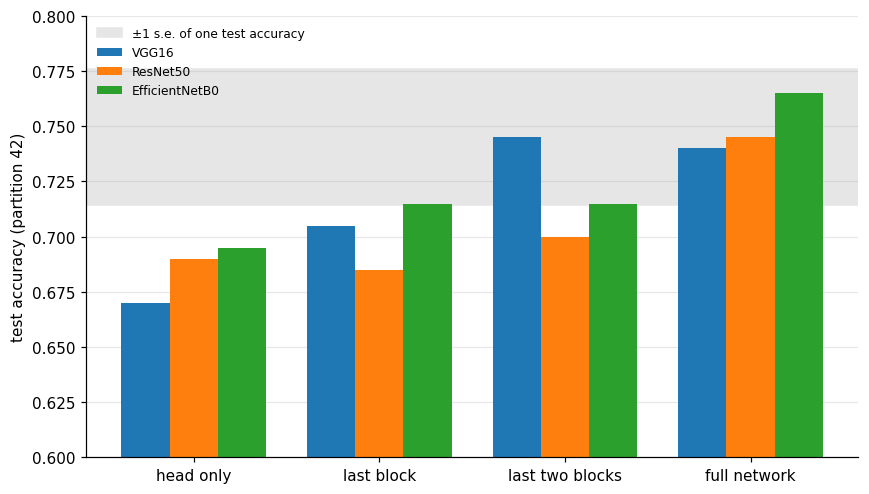

In [13]:
strategies = ["head only", "last block", "last two blocks", "full network"]
p_sel = float(t7.loc[t7.key == SEL, "test_acc"].iloc[0]); se = np.sqrt(p_sel * (1 - p_sel) / len(te_y))

fig, ax = plt.subplots(figsize=(8, 4.6)); w = 0.26
ax.axhspan(p_sel - se, p_sel + se, color="0.9", zorder=0, label="±1 s.e. of one test accuracy")
for j, (m, c) in enumerate(zip(["VGG16", "ResNet50", "EfficientNetB0"], ["tab:blue", "tab:orange", "tab:green"])):
    vals = [t7[(t7.Model == m) & (t7.Strategy == s)].test_acc.iloc[0] for s in strategies]
    ax.bar(np.arange(4) + (j - 1) * w, vals, w, label=m, color=c, zorder=2)
ax.set_xticks(range(4)); ax.set_xticklabels(strategies)
ax.set_ylim(0.60, 0.80); ax.set_ylabel("test accuracy (partition 42)")
ax.grid(axis="y", alpha=.3, zorder=1); ax.legend(loc="upper left", frameon=False, fontsize=8)
fig.tight_layout(); fig.savefig(WORK_DIR / "task2_fig_strategies.png", dpi=200); plt.show()

### Is the selection reliable?
The validation set has only 80 songs, so taking the maximum over 12 noisy values gives an optimistic estimate: the configuration that wins on validation does so partly by chance. Two checks: the rank correlation between validation and test accuracy over the 12 configurations, and the Wilson interval of the selected model.

In [14]:
rho, pval = spearmanr(t7.val_acc, t7.test_acc)
print(f"Spearman correlation validation vs test over the 12 configurations: rho = {rho:.2f} (p = {pval:.3f})")

sel = t7[t7.key == SEL].iloc[0]
n_ok = int(round(sel.test_acc * len(te_y))); lo, hi = wilson_ci(n_ok, len(te_y))
print(f"Selected: {SEL} | val acc {sel.val_acc:.3f} -> test acc {sel.test_acc:.3f} "
      f"(Wilson 95% CI [{lo:.3f}, {hi:.3f}]) | gap {100 * (sel.val_acc - sel.test_acc):.1f} pp")

print("\nBest configuration of each network (by test accuracy) vs its head-only baseline:")
for m in ["VGG16", "ResNet50", "EfficientNetB0"]:
    d = t7[t7.Model == m]; head = d[d.Strategy == "head only"].test_acc.iloc[0]; b = d.loc[d.test_acc.idxmax()]
    print(f"  {m:15s} head only {head:.3f} -> {b.Strategy:16s} {b.test_acc:.3f}  (+{100 * (b.test_acc - head):.1f} pp)")

Spearman correlation validation vs test over the 12 configurations: rho = 0.64 (p = 0.024)
Selected: vgg16_block45 | val acc 0.812 -> test acc 0.745 (Wilson 95% CI [0.680, 0.800]) | gap 6.8 pp

Best configuration of each network (by test accuracy) vs its head-only baseline:
  VGG16           head only 0.670 -> last two blocks  0.745  (+7.5 pp)
  ResNet50        head only 0.690 -> full network     0.745  (+5.5 pp)
  EfficientNetB0  head only 0.695 -> full network     0.765  (+7.0 pp)


### Selected model on the test set

              precision    recall  f1-score   support

       blues      0.706     0.600     0.649        20
   classical      1.000     1.000     1.000        20
     country      0.609     0.700     0.651        20
       disco      0.632     0.600     0.615        20
      hiphop      0.750     0.750     0.750        20
        jazz      0.870     1.000     0.930        20
       metal      1.000     0.850     0.919        20
         pop      0.652     0.750     0.698        20
      reggae      0.739     0.850     0.791        20
        rock      0.467     0.350     0.400        20

    accuracy                          0.745       200
   macro avg      0.742     0.745     0.740       200
weighted avg      0.742     0.745     0.740       200



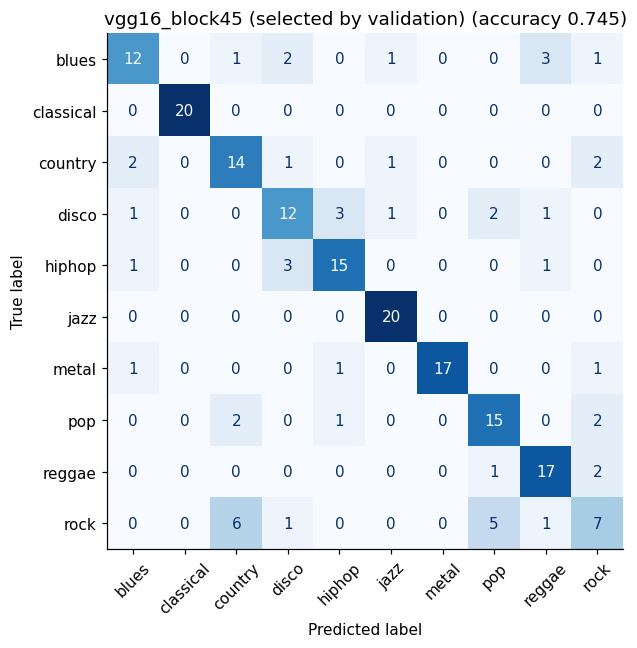

In [15]:
res_sel = res_from_saved(SEL)                      # test probabilities stored by run_and_log
evaluate(res_sel, f"{SEL} (selected by validation)", fig_name=f"task2_fig_confusion_{SEL}.png")
if SEL in results:                                 # training curves only exist if it was trained in this session
    plot_history(results[SEL], SEL)

## SpecAugment check

The CNN of Task 1 is trained with SpecAugment-style masking, whereas the networks above are not. To check whether this explains part of the difference, **only the selected configuration** is repeated with the same masking (one frequency band and one time band of up to 12.5 % of each axis, filled with the image mean, training set only). The result is stored as `<name>_aug`; nothing already run is modified.

In [ ]:
backbone, cfg = CONFIGS[SEL]
AUG_KEY = f"{SEL}_aug"
print("Repeating with augmentation:", SEL, cfg)

AUGMENT = True
try:
    run_and_log(AUG_KEY, backbone, **cfg)
finally:
    AUGMENT = False          # the rest of the session trains without augmentation again

show_runs()[lambda d: d.model.isin([SEL, AUG_KEY])]

Repeating with augmentation: vgg16_block45 {'unfreeze_last': 8}
[vgg16_block45_aug] already in runs.csv -> not retrained (force=True to repeat)
Epoch 1/30
23/23 - 14s - 609ms/step - accuracy: 0.0932 - loss: 9.9073 - val_accuracy: 0.1500 - val_loss: 5.4781
Epoch 2/30
23/23 - 4s - 161ms/step - accuracy: 0.1433 - loss: 7.0102 - val_accuracy: 0.2500 - val_loss: 3.8125
Epoch 3/30
23/23 - 4s - 184ms/step - accuracy: 0.2017 - loss: 5.8268 - val_accuracy: 0.2750 - val_loss: 3.1619
Epoch 4/30
23/23 - 4s - 164ms/step - accuracy: 0.2462 - loss: 5.0954 - val_accuracy: 0.3875 - val_loss: 2.5121
Epoch 5/30
23/23 - 5s - 226ms/step - accuracy: 0.2962 - loss: 4.3333 - val_accuracy: 0.4125 - val_loss: 2.7104
Epoch 6/30
23/23 - 3s - 151ms/step - accuracy: 0.3352 - loss: 3.9026 - val_accuracy: 0.5000 - val_loss: 2.2929
Epoch 7/30
23/23 - 3s - 143ms/step - accuracy: 0.3449 - loss: 3.6084 - val_accuracy: 0.4625 - val_loss: 2.3850
Epoch 8/30
23/23 - 3s - 140ms/step - accuracy: 0.3769 - loss: 3.4357 - val_acc

## Frozen VGG16 embeddings + classical classifiers

The network is never trained: the 512-dimensional embedding of each spectrogram (global average pooling of the last convolutional block) is extracted once, and logistic regression, an SVM and a random forest are trained on top. This is much cheaper than fine-tuning and answers whether fine-tuning is worth its cost (research question 10). The reported inference time includes extracting the embedding.

In [16]:
def extract_embeddings(name, path_lists):
    # Returns (list of (N, d) matrices, extraction time in seconds)
    Base, prep = BACKBONES[name]
    base = Base(include_top=False, weights=WEIGHTS, input_shape=IMG_SIZE + (3,), pooling="avg")
    outs, t0 = [], time.time()
    for paths in path_lists:
        ds = make_ds(paths, np.zeros(len(paths), dtype=np.int32), prep)    # dummy labels
        outs.append(base.predict(ds, verbose=0))                           # (N, 512) for VGG16
    return outs, time.time() - t0

if sk_done("vgg16emb") and not FORCE_RERUN_SKLEARN:
    print("VGG16 embeddings + classifiers already stored in runs.csv -> not recomputed (FORCE_RERUN_SKLEARN=True to recompute)")
    if SHOW_LOGS: show_log("vgg16emb")
else:
    with capture_log("vgg16emb"):
        (Xtr_v, Xva_v, Xte_v), sec = extract_embeddings("vgg16", [tr_p, va_p, te_p])
        emb_ms_v = sec / (len(tr_p) + len(va_p) + len(te_p)) * 1000
        print(f"VGG16 embeddings: {sec:.0f} s | {emb_ms_v:.0f} ms/song | shape {Xtr_v.shape}")
        run_sk_models("vgg16emb", Xtr_v, Xva_v, Xte_v, emb_ms_v)

VGG16 embeddings + classifiers already stored in runs.csv -> not recomputed (FORCE_RERUN_SKLEARN=True to recompute)
(no stored log for this run)



In [ ]:
# Frozen features + classical classifier vs training only the head vs the selected fine-tuned model
keys = ["vgg16_head", "vgg16emb_logreg", "vgg16emb_svm", "vgg16emb_rf", SEL]
cmp_ = read_runs().set_index("model").loc[keys, ["val_acc", "test_acc", "train_time_s", "infer_ms_per_song"]]
display(cmp_.round({"val_acc": 3, "test_acc": 3, "train_time_s": 1, "infer_ms_per_song": 1}))

## VGGish (audio model): frozen embeddings + classical classifiers

*Exploratory — single partition, not part of the five-partition comparison.*

VGGish is a VGG-like network pretrained on a large collection of **audio**. It takes the waveform at 16 kHz, computes a log-mel spectrogram with 64 bands and returns a 128-dimensional embedding for every 0.96 s. Each song is summarised by the mean and the standard deviation of its embeddings over time (256 numbers). The TensorFlow Hub version cannot be fine-tuned, so it is used as a frozen feature extractor, with the same classical classifiers as above and the same train / validation / test songs.

The WAV files must be in `data/genres_original` . Embeddings are cached in `vggish_*.npz`, so they are computed only once. The reported inference time (about 1 s per song) is dominated by reading and resampling the audio file and is **not comparable** with the image-based times.

In [ ]:
def png_to_wav(p):
    # .../classical/classical00026.png -> genres_original/classical/classical.00026.wav
    p = Path(p); g = p.parent.name
    return WAV_DIR / g / f"{g}.{p.stem[len(g):]}.wav"

def vggish_embeddings():
    # Computes (or loads from the cache) the 256-d VGGish vector of every song. Returns the three matrices and ms/song.
    assert WAV_DIR.exists(), f"WAV files not found in {WAV_DIR}: upload data/genres_original to Drive"
    try:
        import tensorflow_hub as hub, librosa
    except ImportError:
        import subprocess, sys
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "tensorflow_hub", "librosa"], check=True)
        import tensorflow_hub as hub, librosa
    try:
        vggish = hub.load("https://tfhub.dev/google/vggish/1")
    except Exception as e:
        print("tfhub.dev failed, trying the Kaggle URL:", repr(e)[:200])
        vggish = hub.load("https://www.kaggle.com/models/google/vggish/tensorFlow2/vggish/1")

    def embed_song(wav_path):
        y, _ = librosa.load(wav_path, sr=16000, mono=True)
        return vggish(y.astype(np.float32)).numpy()                       # (n_frames, 128)

    def embed_split(paths, cache_file):
        cache_file = WORK_DIR / cache_file
        if cache_file.exists():
            d = np.load(cache_file)
            assert len(d["X"]) == len(paths), f"{cache_file.name} does not match the split: delete it from Drive"
            return d["X"], float(d["sec"])
        t0, X = time.time(), []
        for i, p in enumerate(paths):
            wav = png_to_wav(p)
            assert wav.exists(), f"Not found: {wav}"
            fr = embed_song(wav)
            X.append(np.concatenate([fr.mean(0), fr.std(0)]))
            if i % 100 == 0: print(f"{cache_file.stem}: {i}/{len(paths)}")
        X, sec = np.array(X), time.time() - t0
        np.savez(cache_file, X=X, sec=sec)
        return X, sec

    Xtr, s1 = embed_split(tr_p, "vggish_train.npz")
    Xva, s2 = embed_split(va_p, "vggish_val.npz")
    Xte, s3 = embed_split(te_p, "vggish_test.npz")
    ms = (s1 + s2 + s3) / (len(tr_p) + len(va_p) + len(te_p)) * 1000
    print(f"VGGish embeddings: {s1 + s2 + s3:.0f} s in total | {ms:.0f} ms/song | shape {Xtr.shape}")
    return Xtr, Xva, Xte, ms

if sk_done("vggish") and not FORCE_RERUN_SKLEARN:
    print("VGGish classifiers already stored in runs.csv -> not recomputed (FORCE_RERUN_SKLEARN=True to recompute)")
    if SHOW_LOGS: show_log("vggish")
else:
    with capture_log("vggish"):
        Xtr_g, Xva_g, Xte_g, emb_ms_g = vggish_embeddings()
        run_sk_models("vggish", Xtr_g, Xva_g, Xte_g, emb_ms_g)

VGGish classifiers already stored in runs.csv -> not recomputed (FORCE_RERUN_SKLEARN=True to recompute)
vggish_train: 0/719
vggish_train: 100/719
vggish_train: 200/719
vggish_train: 300/719
vggish_train: 400/719
vggish_train: 500/719
vggish_train: 600/719
vggish_train: 700/719
vggish_val: 0/80
vggish_test: 0/200
vggish_test: 100/200
VGGish embeddings: 1001 s in total | 1002 ms/song | shape (719, 256)
vggish_logreg: val=0.900 | test=0.830
vggish_svm: val=0.912 | test=0.840
vggish_rf: val=0.900 | test=0.835



In [17]:
# Best vision model (selected by validation) vs VGGish
keys = [SEL, "vggish_logreg", "vggish_svm", "vggish_rf"]
display(read_runs().set_index("model").loc[keys, ["val_acc", "test_acc", "train_time_s", "infer_ms_per_song"]]
        .round({"val_acc": 3, "test_acc": 3, "train_time_s": 1, "infer_ms_per_song": 1}))

,val_acc,test_acc,train_time_s,infer_ms_per_song
model,,,,
vgg16_block45,0.812,0.745,160.5,4.0
vggish_logreg,0.900,0.830,0.6,1002.0
vggish_svm,0.912,0.840,0.4,1002.1
vggish_rf,0.900,0.835,3.0,1002.1


## Final table

In [18]:
show_runs()      # all runs (including previous sessions), sorted by validation accuracy

,model,val_acc,test_acc,train_time_s,infer_ms_per_song,params
0,vggish_svm,0.9125,0.840,0.3691,1002.1471,NaN
1,vggish_logreg,0.9000,0.830,0.5994,1002.0210,2570.0
2,vggish_rf,0.9000,0.835,3.0415,1002.1180,NaN
3,vgg16_block45,0.8125,0.745,160.5390,3.9508,14719818.0
4,vgg16_full,0.7750,0.740,251.1700,3.8970,14719818.0
5,effnetb0_full,0.7750,0.765,223.1002,1.3568,4062381.0
6,resnet50_head,0.7625,0.690,83.1308,2.7564,23608202.0
7,resnet50_full,0.7625,0.745,211.9561,3.1437,23608202.0
8,vgg16_block45_aug,0.7625,0.720,176.8876,3.9031,14719818.0
9,resnet50_conv5,0.7500,0.685,138.7197,2.9742,23608202.0


## Notes

All results here use the main partition (seed 42). The selected configuration is repeated on five partitions in the multi-partition notebook, and compared with the CNN of Task 1 and the Lab 1 descriptor models in `analysis`. Also, **VGGish** is exploratory, and its inference time is dominated by audio loading. Training logs are stored in `training_logs.json` and replayed for skipped runs. To retrain a run on purpose, call `run_and_log("<name>", "<backbone>", force=True, ...)`: its row in `runs.csv` and its log are overwritten. Finally, GPU kernels are not fully deterministic, so retraining a configuration can change its test accuracy by a few songs (one song = 0.5 pp). This is why finished runs are stored and reused instead of being retrained.

**Next notebooks:** `lab1_retraining` → `multiseed_retraining` → `analysis`.